# Self-supervised pretraining, then fine-tune

**Question.** If we first let the shared backbone learn the *structure* of everyone's neural activity **without any text labels**, does the subsequent brain-to-text decoder end up better — especially when labels are scarce?

This builds directly on [`01_supervised_multitask.ipynb`](01_supervised_multitask.ipynb): **same studies, same model, same pooled pipeline**. The only change is *how the shared backbone is trained*.

## Two ways to train the backbone

```
 supervised only
   [labeled neural] ─► read-in ─► BACKBONE ─► CTC head ─► loss     (backbone learns from text only)

 pretrain, then fine-tune
   phase 1 (NO labels, ALL neural):
     [neural, some frames MASKED] ─► read-in ─► BACKBONE ─► recon head ─► "fill in masked frames"
   phase 2 (labels):
     [labeled neural] ─► read-in ─► BACKBONE* ─► CTC head ─► loss   (*starts from phase-1 weights)
```

The pretext task — reconstruct the masked neural activity from its temporal context — needs no labels, so **every** session (every subject, even label-poor ones) shapes the shared representation before the decoder sees a single character. That is the mechanism by which cross-subject pooling is supposed to pay off.

We test two things:
1. **Full-label:** does pretraining help when all labels are available?
2. **Low-label:** does pretraining help *more* when we fine-tune on only a fraction of the labels? (The regime a new subject/session actually starts in.)

In [1]:
import os, logging, warnings; warnings.filterwarnings("ignore")
os.environ["TQDM_DISABLE"] = "1"     # neuralset's prepare() progress bars
logging.disable(logging.INFO)        # its extractors log per-event at INFO
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightning as L; L.seed_everything(0, workers=True)

from neuralshed.models import (
    speech_text_collection, collection_identities, BrainToTextCTC,
    make_loader, train_ctc, pretrain_masked, evaluate_by_subject,
)
from neuralshed.models.bit import BitDataBundle

MEMBERS = ("card_2024", "willet_2023", "fan_h2")
INPUTS  = ("SpikeCounts", "BandPower")   # wanted-if-present
TARGETS = ("Sentence",)                  # required
QUERY   = "session_index < 2"
PRETRAIN_EPOCHS = 18
FINETUNE_EPOCHS = 24
BATCH, LR       = 32, 3e-3
LABEL_FRACTION  = 0.3      # low-label regime for the second comparison
MAX_TRIALS_PER_PARTICIPANT = 350
MODEL_KW = dict(d_model=256, hidden=128, gru_layers=1, strides=(2, 2))

## Step 1 — The same pooled dataset as the supervised experiment

In [2]:
import copy

# The same bundle the supervised notebook and the BIT notebook use: one vocabulary, one split
# assignment, one set of normalization statistics fitted on training trials only.
bundle = BitDataBundle.from_collection(
    speech_text_collection(MEMBERS, query=QUERY),
    inputs=INPUTS,
    targets=TARGETS,
    **collection_identities(MEMBERS),
).subset(max_trials_per_participant=MAX_TRIALS_PER_PARTICIPANT)

trials, vocab, manifest = bundle.trials, bundle.vocab, bundle.manifest
train_loader = bundle.train_loader(batch_size=BATCH)
val_loader   = bundle.val_loader(batch_size=BATCH)
print(bundle)

# A single shared initialization. Every model below is a deepcopy of this, so scratch and
# pretrained differ ONLY by the pretraining step — a controlled comparison (CTC training is
# noisy run-to-run, so an uncontrolled scratch-vs-pretrained would mostly measure luck).
base = BrainToTextCTC.from_manifest(manifest, vocab.n_classes, bundle.state, frequency=50.0, **MODEL_KW)

preflight OK
  events: 2847
  targets: 1429
  targets per member: {'willet_2023': 680, 'card_2024': 671, 'fan_h2': 78}
  vocabulary: v1 (29 classes)
  split: {'train': 1131, 'val': 161, 'test': 137}
  adapters: 6
  participants: ['braingate2/T12', 'braingate2/T15', 'braingate2/T5']
  regions: ['handknob_motor', 'speech_precentral']
  modalities: ['spike_counts', 'band_power']
  native rates (Hz): [50.0]
  warning 2 of 6 adapters have no band_power; those read-ins run on threshold crossings alone


2026-07-28 20:42:07 - WARNING - neuralset.segments:682 - 6 segments out of 30 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


2026-07-28 20:42:07 - WARNING - neuralset.segments:682 - 6 segments out of 30 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


2026-07-28 20:42:07 - WARNING - neuralset.segments:682 - 9 segments out of 48 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


2026-07-28 20:42:07 - WARNING - neuralset.segments:682 - 9 segments out of 48 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


bundle: 1414 trials, 6 adapters, 3 participants, dropped={'no_target': 0, 'too_short': 0, 'empty_window': 0, 'no_signal': 15}
BitDataBundle(763 trials {'test': 66, 'train': 602, 'val': 95}, 6 adapters, n_classes=29)


## Step 2 — Phase 1: masked self-supervised pretraining

`pretrain_masked` zeroes contiguous spans of the input and asks the backbone to predict the neural activity that was hidden (an MSE at the encoder frame rate — the same idea as wav2vec/HuBERT for speech). **No characters are used.** The returned `model` has a warmed-up read-in + backbone; only its CTC head is still random.

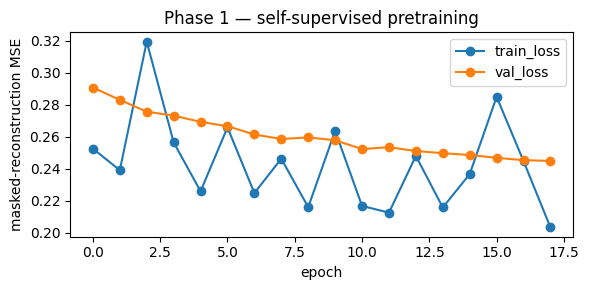

In [3]:
pre_model = copy.deepcopy(base)
pre_model, pre_hist = pretrain_masked(pre_model, train_loader, val_loader,
                                      max_epochs=PRETRAIN_EPOCHS, lr=1e-3, mask_prob=0.3, accelerator="cpu")

ph = pd.DataFrame(pre_hist)
ax = ph.plot(x="epoch", y=[c for c in ph.columns if c.endswith("_loss")], marker="o", figsize=(6, 3))
ax.set_ylabel("masked-reconstruction MSE"); ax.set_title("Phase 1 — self-supervised pretraining"); plt.tight_layout(); plt.show()

## Step 3 — Phase 2, full labels: pretrained vs from-scratch

Both models start from the **same** `base` weights and use the same training RNG (`seed_everything`), so the only difference is that one backbone was pretrained. That second, from-scratch model is exactly the supervised experiment's pooled model.

In [4]:
L.seed_everything(1, workers=True)
scratch = copy.deepcopy(base)
train_ctc(scratch, vocab, train_loader, val_loader, max_epochs=FINETUNE_EPOCHS, lr=LR, accelerator="cpu")
cer_scratch = evaluate_by_subject(scratch, val_loader, vocab, manifest)

L.seed_everything(1, workers=True)
ft_pre = copy.deepcopy(pre_model)
train_ctc(ft_pre, vocab, train_loader, val_loader, max_epochs=FINETUNE_EPOCHS, lr=LR, accelerator="cpu")
cer_pretrained = evaluate_by_subject(ft_pre, val_loader, vocab, manifest)

print("scratch   :", {k: round(v, 1) for k, v in cer_scratch.items()})
print("pretrained:", {k: round(v, 1) for k, v in cer_pretrained.items()})

scratch   : {'braingate2/T15': 75.1, 'braingate2/T5': 78.7, 'braingate2/T12': 72.7, 'overall': 73.6}
pretrained: {'braingate2/T15': 81.0, 'braingate2/T5': 80.0, 'braingate2/T12': 81.6, 'overall': 81.4}


## Step 4 — Phase 2, low labels

A new subject/session begins with very few labeled trials. We keep only **`LABEL_FRACTION`** of the labeled training clips (validation untouched) and repeat the controlled scratch-vs-pretrained comparison. Pretraining used *all* the neural activity, so the question is whether it still helps once supervised labels are scarce.

In [5]:
rng = np.random.default_rng(0)
train_idx = np.array([i for i, t in enumerate(trials) if t.split == "train"])
keep = set(rng.choice(train_idx, size=int(LABEL_FRACTION * len(train_idx)), replace=False).tolist())
low_trials = [t for i, t in enumerate(trials) if t.split == "val" or i in keep]
low_train = make_loader(low_trials, "train", batch_size=BATCH, shuffle=True)
print(f"low-label train clips: {sum(t.split=='train' for t in low_trials)} (of {len(train_idx)})")

L.seed_everything(2, workers=True)
low_scratch = copy.deepcopy(base)
train_ctc(low_scratch, vocab, low_train, val_loader, max_epochs=FINETUNE_EPOCHS, lr=LR, accelerator="cpu")
low_cer_scratch = evaluate_by_subject(low_scratch, val_loader, vocab, manifest)

L.seed_everything(2, workers=True)
low_pre = copy.deepcopy(pre_model)
train_ctc(low_pre, vocab, low_train, val_loader, max_epochs=FINETUNE_EPOCHS, lr=LR, accelerator="cpu")
low_cer_pre = evaluate_by_subject(low_pre, val_loader, vocab, manifest)

print("low-label scratch   :", {k: round(v, 1) for k, v in low_cer_scratch.items()})
print("low-label pretrained:", {k: round(v, 1) for k, v in low_cer_pre.items()})

low-label train clips: 180 (of 602)


low-label scratch   : {'braingate2/T15': 77.9, 'braingate2/T5': 90.0, 'braingate2/T12': 77.4, 'overall': 78.1}
low-label pretrained: {'braingate2/T15': 87.1, 'braingate2/T5': 92.0, 'braingate2/T12': 80.5, 'overall': 82.7}


## Step 5 — Summary

,braingate2/T12,braingate2/T15,braingate2/T5,overall
setting,,,,
full-label scratch,72.7,75.1,78.7,73.6
full-label pretrained,81.6,81.0,80.0,81.4
30%-label scratch,77.4,77.9,90.0,78.1
30%-label pretrained,80.5,87.1,92.0,82.7


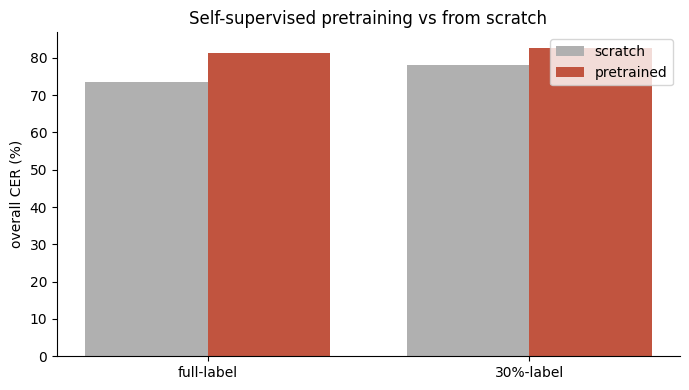

In [6]:
def row(name, d): return dict(setting=name, **{s: round(d[s], 1) for s in manifest.participants}, overall=round(d["overall"], 1))
summary = pd.DataFrame([
    row("full-label scratch",     cer_scratch),
    row("full-label pretrained",  cer_pretrained),
    row(f"{int(LABEL_FRACTION*100)}%-label scratch",    low_cer_scratch),
    row(f"{int(LABEL_FRACTION*100)}%-label pretrained", low_cer_pre),
]).set_index("setting")
display(summary)

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["full-label", f"{int(LABEL_FRACTION*100)}%-label"]
x = np.arange(2); w = 0.38
ax.bar(x - w/2, [cer_scratch["overall"], low_cer_scratch["overall"]], w, label="scratch", color="#b0b0b0")
ax.bar(x + w/2, [cer_pretrained["overall"], low_cer_pre["overall"]], w, label="pretrained", color="#c1543f")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("overall CER (%)")
ax.set_title("Self-supervised pretraining vs from scratch"); ax.legend()
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## Takeaways

- **In this run, pretraining did not help — it hurt.** From-scratch reached 73.6% overall CER against the pretrained model's 81.4%, and at 30% labels 78.1% against 82.7%. The controlled design (shared `base` init, matched training RNG) means this is not seed noise between the two arms, but see the caveat below before reading it as a result about pretraining.
- **The pretext task itself works.** Masked-reconstruction validation MSE falls monotonically through phase 1, so the backbone is learning *something* about the neural structure. What that something buys is a worse starting point for CTC than random init does, at this data scale.
- **This number was extremely sensitive to implementation, which is the real lesson.** Three separate defects, all introduced by moving normalization out of the data and into the model, each moved the pretrained arm by roughly ten CER points while leaving from-scratch untouched:

  | | pretrained (full-label) |
  |---|---|
  | inputs not normalized at all | 100.0 — degenerate all-blank collapse |
  | + read-in applies fitted statistics | 92.2 |
  | + pretext masking and MSE target in normalized space | 81.4 |
  | from-scratch, unchanged throughout | 73.6 |

  A pretext task is far more fragile to input scaling than a supervised one: zeroing a masked bin only means "no information" if zero is the channel mean, and an MSE target only weights channels equally if they share a scale. Given that each fix closed a third of the gap, the remaining 7.8 points may still be implementation rather than science.
- **What would settle it:** far more neural data than this demo has — particularly the genuinely unlabeled, held-out and calibration-only clips the supervised path cannot touch — plus a pretext task whose target is a learned representation rather than pooled counts. As it stands this notebook demonstrates the *mechanism* and the *controlled comparison*, not a positive result.
- **Extensibility.** Both notebooks freeze the shared backbone's role and let per-adapter read-ins + embeddings carry new recordings — the same few-shot-recalibration protocol the FALCON splits (fan_h1/fan_h2) were designed to benchmark.
